<a href="https://colab.research.google.com/github/Thedreamaker/Qiskit_Learning/blob/basics/Basics_Teleportation/Qiskit_Teleportation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 54.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.0 MB/s eta 0:00:00


Teleportation Results: {'110 10': 279, '100 00': 254, '111 11': 231, '101 01': 260}


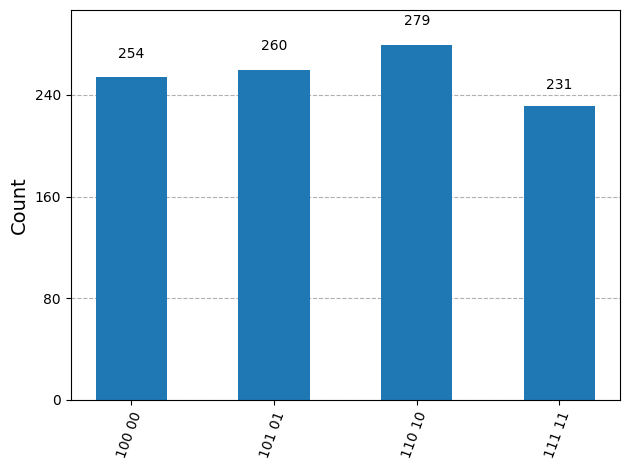

In [3]:
import qiskit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
#def run_quantum_experiment():
# 3 qubits: q0 (Alice's message), q1 (Alice's entangled half), q2 (Bob's entangled half)
# 2 classical bits to send the message instructions
qc_teleport = QuantumCircuit(3, 2)

# Step 1: Prepare the secret message on q0 (Flip it to |1>)
qc_teleport.x(0)
qc_teleport.barrier()

# Step 2: Create a Bell pair (entanglement) between q1 and q2
qc_teleport.h(1)
qc_teleport.cx(1, 2)
qc_teleport.barrier()

# Step 3: Alice entangles her secret message (q0) with her shared pair (q1)
qc_teleport.cx(0, 1)
qc_teleport.h(0)
qc_teleport.barrier()

# Step 4: Alice measures her two qubits into classical bits
qc_teleport.measure(0, 0)
qc_teleport.measure(1, 1)
qc_teleport.barrier()

# Step 5: Bob modifies q2 using conditional logic based on Alice's classical bits
#qc_teleport.cx(1, 2)
#qc_teleport.cz(0, 2)
# Step 5: Bob modifies q2 using your exact classical bit rules!
with qc_teleport.if_test((qc_teleport.clbits[0], 1)):
    qc_teleport.z(2)  # If bit[0] is 1, phase shift q2

with qc_teleport.if_test((qc_teleport.clbits[1], 1)):
    qc_teleport.x(2)  # If bit[1] is 1, NOT gate q2


# Verify the result by measuring Bob's qubit (q2)
qc_teleport_meas = qc_teleport.copy()
qc_teleport_meas.measure_all()

# Run Simulation
sim = AerSimulator()
counts_teleport = sim.run(qc_teleport_meas, shots=1024).result().get_counts()
print("Teleportation Results:", counts_teleport)
plot_histogram(counts_teleport)